# 🔍 02. Unsupervised Anomaly Detection: Deep Autoencoder
### Project: XAI System in Banking: AI Anomaly-Driven Credit Card Fraud Detection and Interpretation
**Objective:** Train an unsupervised Deep Autoencoder strictly on legitimate banking transactions to learn normal manifold dynamics, compute reconstruction error residuals, and establish dynamic anomaly thresholds.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

from src.data.preprocessing import DataPipeline
from src.models.autoencoder import DeepAutoencoder
from src.utils.device import get_device

device = get_device("auto")
print(f"Device: {device}")

Device: cpu


## 1. Load Preprocessed Zero-Leakage Dataset splits

In [2]:
pipeline = DataPipeline(processed_dir=str(ROOT_DIR / "data/processed"))
data = pipeline.load_processed()

input_dim = data.X_train.shape[1]
print(f"Features: {input_dim}")
print(f"Normal training samples: {len(data.X_train_normal):,}")
print(f"Test samples: {len(data.X_test):,} (Fraud: {data.y_test.sum():,})")

Features: 33
Normal training samples: 199,020
Test samples: 42,722 (Fraud: 74)


## 2. Load Production Autoencoder Checkpoint & Calibrated Threshold

In [3]:
model_path = ROOT_DIR / "results/models/autoencoder.pt"
autoencoder = DeepAutoencoder(input_dim=input_dim, latent_dim=8).to(device)

if model_path.exists():
    ckpt = torch.load(model_path, map_location=device, weights_only=False)
    state = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt
    autoencoder.load_state_dict(state)
    threshold = ckpt.get("threshold", 1.5048)
    print(f"Loaded trained Autoencoder from {model_path}")
    print(f"Calibrated 98th Percentile Anomaly Threshold: {threshold:.6f}")
else:
    print("Pretrained checkpoint not found; please execute python scripts/train.py first.")

Loaded trained Autoencoder from /home/swayam-shah/repos/XAI-System-in-Banking-AI-Anomaly-Driven-Credit-Card-Fraud-Detection-and-Interpretation/results/models/autoencoder.pt
Calibrated 98th Percentile Anomaly Threshold: 1.504895


## 3. Reconstruction Error Evaluation on Held-out Test Set

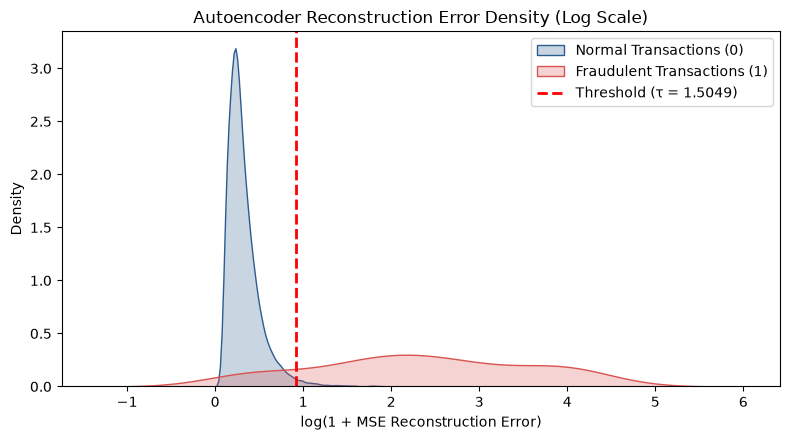

In [4]:
autoencoder.eval()
with torch.no_grad():
    test_tensor = torch.as_tensor(data.X_test, dtype=torch.float32, device=device)
    recon_errors = autoencoder.compute_reconstruction_error(test_tensor, reduction="mean").cpu().numpy()

normal_errors = recon_errors[data.y_test == 0]
fraud_errors = recon_errors[data.y_test == 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.kdeplot(np.log1p(normal_errors), label="Normal Transactions (0)", fill=True, color="#2b5c8f", ax=ax)
sns.kdeplot(np.log1p(fraud_errors), label="Fraudulent Transactions (1)", fill=True, color="#d9534f", ax=ax)
ax.axvline(np.log1p(threshold), color="red", linestyle="--", linewidth=2, label=f"Threshold (τ = {threshold:.4f})")
ax.set_title("Autoencoder Reconstruction Error Density (Log Scale)")
ax.set_xlabel("log(1 + MSE Reconstruction Error)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Latent Space Representation Visualization (t-SNE / PCA Projection)

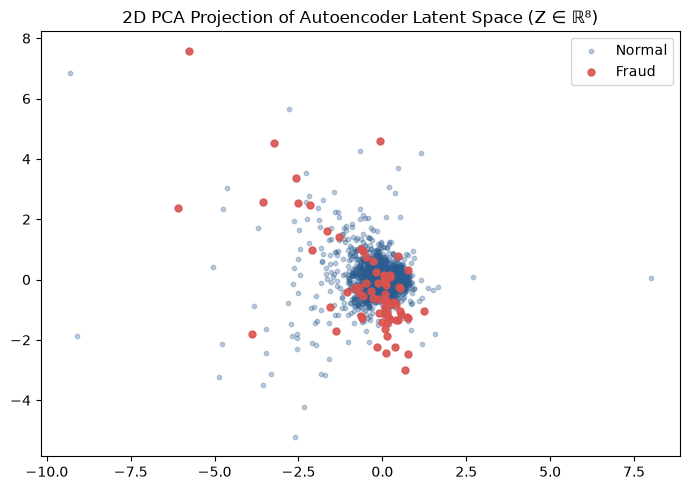

In [5]:
from sklearn.decomposition import PCA

with torch.no_grad():
    latent_z = autoencoder.encode(test_tensor).cpu().numpy()

pca = PCA(n_components=2)
z_2d = pca.fit_transform(latent_z)

fig, ax = plt.subplots(figsize=(7, 5))
norm_mask = (data.y_test == 0)
ax.scatter(z_2d[norm_mask, 0][:3000], z_2d[norm_mask, 1][:3000], c="#2b5c8f", alpha=0.3, s=10, label="Normal")
ax.scatter(z_2d[~norm_mask, 0], z_2d[~norm_mask, 1], c="#d9534f", alpha=0.9, s=25, label="Fraud")
ax.set_title("2D PCA Projection of Autoencoder Latent Space (Z ∈ ℝ⁸)")
ax.legend()
plt.tight_layout()
plt.show()